In [2]:
import pandas as pd
from pathlib import Path
import numpy as np

In [3]:
# Find the metadata CSV
files = list(Path("../data").rglob("driver_imgs_list.csv"))

# Load the dataset
df = pd.read_csv(files[0])

# Check the data
print(df.shape)
df.head()


(22424, 3)


,subject,classname,img
0,p002,c0,img_44733.jpg
1,p002,c0,img_72999.jpg
2,p002,c0,img_25094.jpg
3,p002,c0,img_69092.jpg
4,p002,c0,img_92629.jpg


Checking drivers and classes.

In [4]:
print("Total images:", len(df))
print("Total drivers:", df['subject'].nunique())
print("Total classes:", df["classname"].nunique())

Total images: 22424
Total drivers: 26
Total classes: 10


Step 3 — Split drivers into Train, Validation, and Test
We'll use:
Dataset	Drivers	Purpose
Train	18	Teach the model
Validation	4	Tune the model
Test	4	Final evaluation


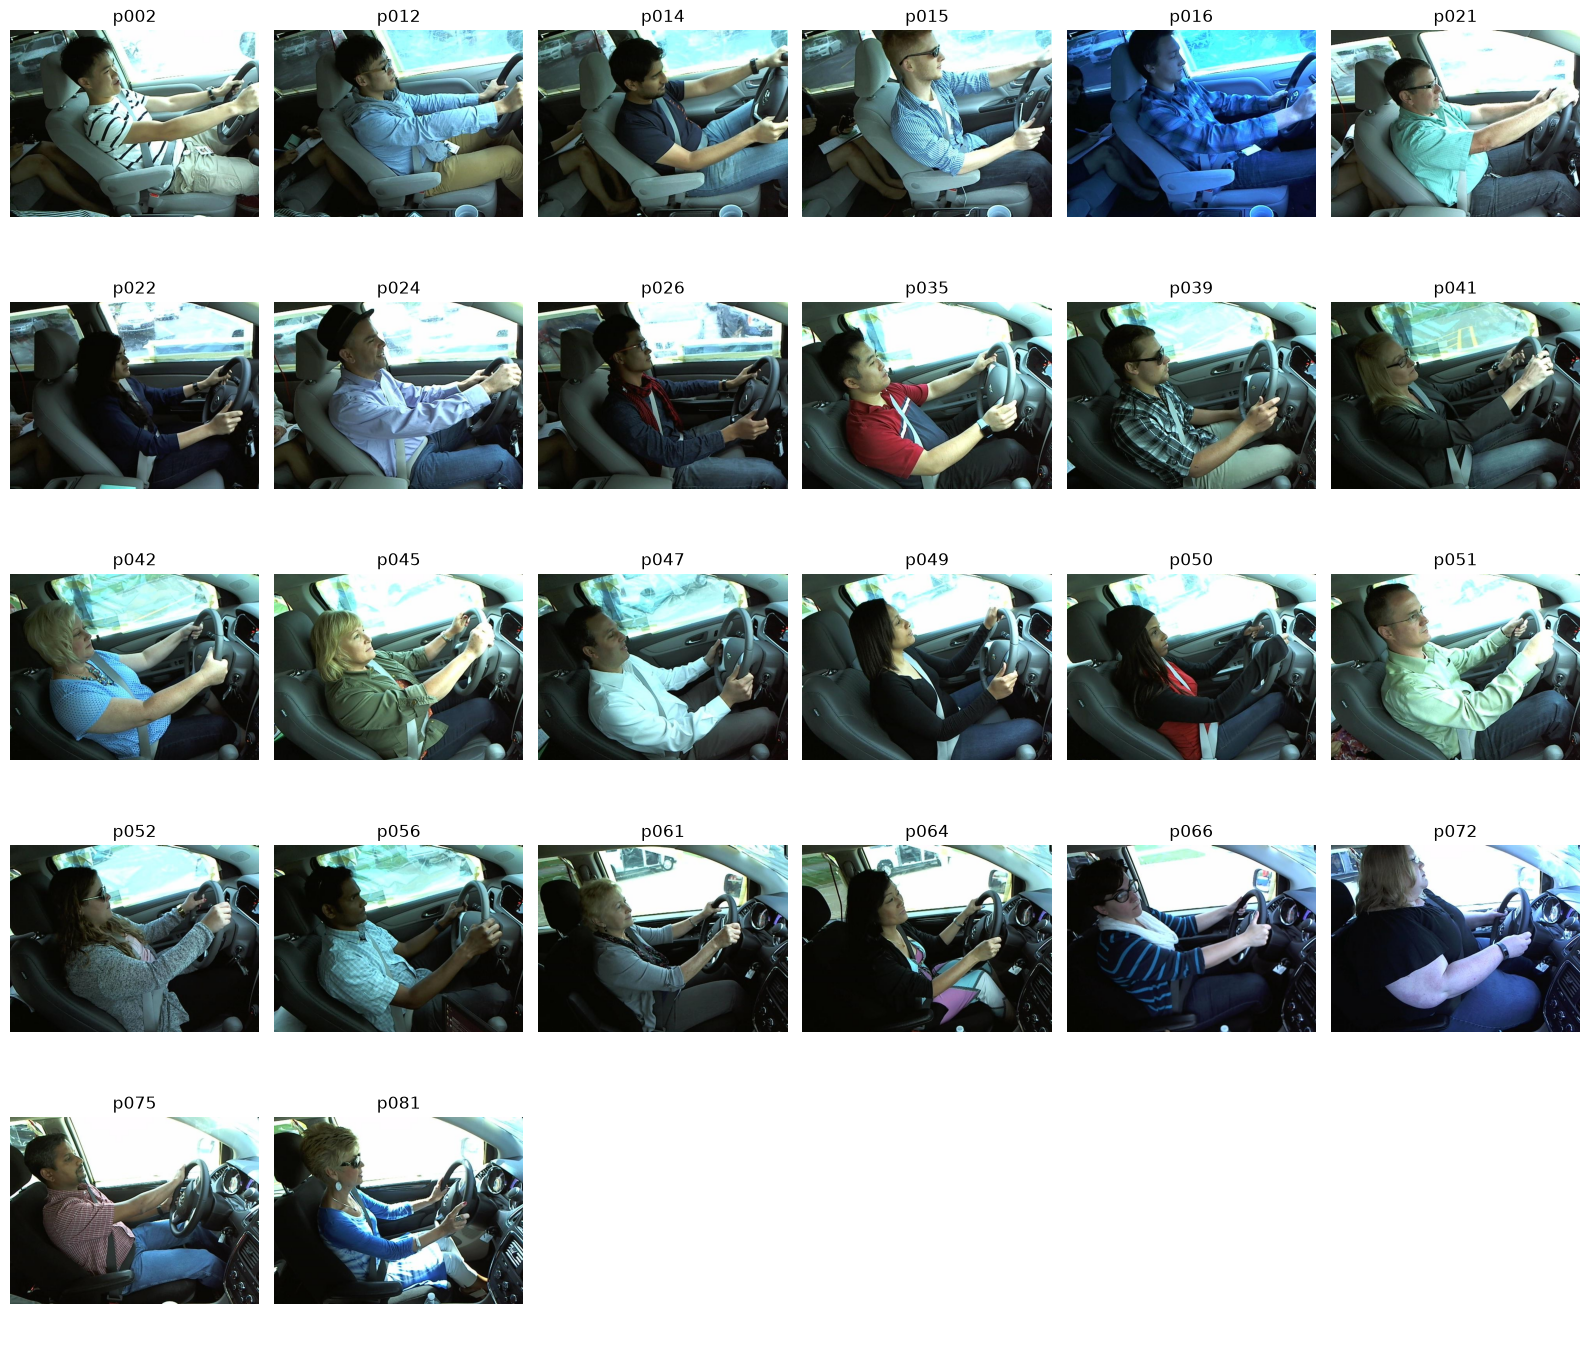

In [5]:
import matplotlib.pyplot as plt

#select one image from each driver
samples = df.drop_duplicates(subset="subject").sort_values("subject")

sample_file = next(Path("../data").rglob(df.iloc[0]["img"]))
image_root = sample_file.parent.parent

fig, axes = plt.subplots(5, 6, figsize=(16, 14))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image_path = image_root / row["classname"] / row["img"]

    image = plt.imread(image_path)
    ax.imshow(image)
    ax.set_title(row["subject"])
    ax.axis("off")

# Hide unused plots
for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()



## Step 4: Split Drivers into Training, Validation, and Test Sets

Let's create three groups:
- 18 drivers for training
- 4 drivers for validation
- 4 drivers for testing

In [6]:
#get all unique driver IDs
drivers = np.sort(df['subject'].unique())

#Randomly shuffle with a fixed seed
rng = np.random.default_rng(seed=42)
rng.shuffle(drivers)

#split drivers into three groups
train_drivers = drivers[:18]
val_drivers = drivers[18:22]
test_drivers = drivers[22:]

print("Training:", train_drivers)
print("Validation:", val_drivers)
print("Testing:", test_drivers)

Training: ['p024' 'p049' 'p064' 'p061' 'p051' 'p021' 'p052' 'p081' 'p039' 'p035'
 'p022' 'p050' 'p015' 'p002' 'p066' 'p056' 'p042' 'p041']
Validation: ['p047' 'p075' 'p014' 'p016']
Testing: ['p072' 'p012' 'p045' 'p026']


In [7]:
#Create a copy of the dataset
df_split = df.copy()

#Assign each image to its driver's group
df_split['split'] = "unassigned"
df_split.loc[df_split["subject"].isin(train_drivers), "split"] = "train"
df_split.loc[df_split["subject"].isin(val_drivers), "split"] = "val"
df_split.loc[df_split["subject"].isin(test_drivers), "split"] = "test"

#Count images in each group
print(df_split["split"].value_counts()  )



split
train    15732
val       3603
test      3089
Name: count, dtype: int64


In [8]:
# Count images in each dataset
print(df_split["split"].value_counts())

# Count unique drivers in each dataset
print(df_split.groupby("split")["subject"].nunique())

# Check that no images remain unassigned
print("Unassigned images:",
      (df_split["split"] == "unassigned").sum())

split
train    15732
val       3603
test      3089
Name: count, dtype: int64
split
test      4
train    18
val       4
Name: subject, dtype: int64
Unassigned images: 0
